# Type d'assistance idéale pour le ménage (v6)
### Classification multi classe

Dans mon mémoire, deux types de classification étaient possibles : **binaire** (ménage éligible ou pas) et **multi classe** (type d'assistance idéale pour le ménage). Le notebook `ciblage_avec_ml_v6.ipynb` traite la classification binaire. Ce notebook traite la classification multi classe : sur base des réponses de l'enquête ménage, quel type d'assistance répond le mieux au besoin principal du ménage ?

Lors de la vérification approfondie, le comité relève le **besoin principal** de chaque ménage visité (colonne `assistance_ideale`). Il y a 7 types d'assistance :

| Code | Type d'assistance |
|---|---|
| `vivres` | Vivres / cash alimentaire |
| `moyens_existence` | Moyens d'existence (semences, activité génératrice de revenu) |
| `abri_ame` | Abri et articles ménagers essentiels |
| `education` | Éducation (kits et frais scolaires) |
| `sante_nutrition` | Santé et nutrition |
| `eau_hygiene` | Eau, hygiène et assainissement |
| `protection` | Protection |

Pour un ménage éligible, c'est l'assistance à lui donner. Pour un ménage non éligible, c'est son besoin principal : utile pour l'orienter vers un autre partenaire.

Comme pour l'éligibilité, la grille Excel n'est pas donnée au modèle.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#supprimer les warnings
import warnings
warnings.filterwarnings("ignore")

### Importer et lire les données

In [3]:
#importer les données
# le fichier est créé par le notebook generation_donnees_ciblage_v6.ipynb
df = pd.read_csv("./data/ciblage_v6.csv")
df.shape

(100000, 80)

In [4]:
df[['id_menage', 'statut_menage', 'taille_menage', 'eligible', 'assistance_ideale']].head()

,id_menage,statut_menage,taille_menage,eligible,assistance_ideale
0,MEN_000001,resident,2,0,protection
1,MEN_000002,resident,2,0,sante_nutrition
2,MEN_000003,resident,4,0,abri_ame
3,MEN_000004,deplace,5,1,vivres
4,MEN_000005,retourne,4,0,eau_hygiene


### <font color = 'orange'>Exploration des données<font>

##### <font color = 'magenta'>La variable cible

In [5]:
# fonction de countplot
import plotly.express as px
def countplot_func(col, data = df):
  val = data[col].value_counts()
  fig = px.bar(x=val.index, y=val.values, color = val.values, text_auto=True, title=col)
  fig.show()

In [6]:
# Nombre de ménages dans chaque classe
df.assistance_ideale.value_counts()

assistance_ideale
abri_ame            19789
eau_hygiene         18059
vivres              16574
moyens_existence    14944
education           12112
protection           9507
sante_nutrition      9015
Name: count, dtype: int64

In [7]:
countplot_func("assistance_ideale")

In [8]:
# besoin principal des ménages éligibles seulement
countplot_func("assistance_ideale", df[df.eligible == 1])

Les classes ne sont pas trop déséquilibrées : la plus petite représente environ 9 % des ménages. Chez les ménages éligibles, les vivres et les moyens d'existence prennent plus de place : ce sont les ménages les plus touchés par l'insécurité alimentaire.

##### <font color = 'magenta'>Ce qui distingue chaque type d'assistance

In [9]:
# moyenne de quelques réponses pour chaque type d'assistance (normalisée entre 0 et 1 pour comparer)
df_expl = df.copy()
df_expl['sans_latrine'] = (df_expl.type_latrine == 'aucune').astype(int)
df_expl['malnutrition'] = (df_expl.enfant_malnutrition_depiste == 'oui').astype(int)
df_expl['incident_securite'] = (df_expl.incident_securite_3_mois == 'oui').astype(int)
df_expl['sans_abri_ou_fortune'] = df_expl.type_logement.isin(['sans_abri', 'abri_fortune']).astype(int)
df_expl['perte_revenu'] = (df_expl.perte_revenu_6_mois == 'oui').astype(int)
cols = ['jours_viande_poisson', 'rcsi_reduction_portions', 'perte_revenu', 'sans_abri_ou_fortune', 'articles_essentiels',
        'enfants_non_scolarises', 'malnutrition', 'temps_collecte_eau_min', 'sans_latrine', 'incident_securite']
profil = df_expl.groupby('assistance_ideale')[cols].mean()
profil = (profil - profil.min()) / (profil.max() - profil.min())
fig = px.imshow(profil, color_continuous_scale='Blues', aspect='auto', title="Profil moyen de chaque type d'assistance (0 = plus bas, 1 = plus haut)")
fig.show()

Chaque type d'assistance a son profil : les ménages "éducation" ont beaucoup d'enfants non scolarisés, les ménages "eau et hygiène" passent beaucoup de temps à chercher l'eau et n'ont pas de latrine, les ménages "abri" vivent en abri de fortune avec peu d'articles essentiels. Mais un même ménage a souvent plusieurs besoins : le comité retient le plus fort, et c'est cette comparaison entre secteurs que le modèle doit apprendre.

##### <font color = 'magenta'>Les indicateurs standard

Avec les réponses, on calcule les indicateurs classiques de l'humanitaire. Ce ne sont pas des données externes : ce sont des calculs sur les réponses du ménage.
- **FCS** (score de consommation alimentaire) : nombre de jours de consommation de chaque groupe d'aliments, pondéré (poids du PAM) ;
- **rCSI** (indice réduit des stratégies d'adaptation) : nombre de jours de chaque stratégie, pondéré ;
- **revenu par personne**, **part des enfants non scolarisés** et **dette rapportée au revenu**.

Ils aident le modèle à comparer les secteurs entre eux. L'API calcule exactement les mêmes (`app/indicateurs.py`).

In [10]:
df['fcs'] = (2 * df.jours_cereales + 3 * df.jours_legumineuses + 4 * df.jours_lait + 4 * df.jours_viande_poisson
             + df.jours_legumes + df.jours_fruits + 0.5 * df.jours_huile + 0.5 * df.jours_sucre)
df['rcsi'] = (df.rcsi_aliments_moins_chers + 2 * df.rcsi_emprunt_nourriture + df.rcsi_reduction_portions
              + 3 * df.rcsi_adultes_pour_enfants + df.rcsi_moins_de_repas)
df['revenu_par_personne'] = df.revenu_30j_usd / df.taille_menage
df['part_non_scolarises'] = df.enfants_non_scolarises / np.maximum(df.enfants_5_17, 1)
df['dette_sur_revenu'] = df.dette_usd / (df.revenu_30j_usd + 20)
df[['fcs', 'rcsi', 'revenu_par_personne', 'part_non_scolarises', 'dette_sur_revenu']].describe().T

,count,mean,std,min,25%,50%,75%,max
fcs,100000.0,43.785620,11.673330,6.5,35.50,44.000000,52.000000,94.0
rcsi,100000.0,11.465320,7.739918,0.0,5.00,10.000000,16.000000,50.0
revenu_par_personne,100000.0,13.616153,13.764691,0.0,5.75,10.142857,17.250000,450.0
part_non_scolarises,100000.0,0.223835,0.339418,0.0,0.00,0.000000,0.500000,1.0
dette_sur_revenu,100000.0,1.295847,3.185507,0.0,0.00,0.213445,1.257698,125.2


In [11]:
# Fonction permettant de visualiser les boxplots par type d'assistance
# (sur 20 000 ménages tirés au hasard : avec les 100 000, le notebook devient très lourd)
echantillon = df.sample(20000, random_state = 42)
def boxplot_func(col):
    fig = px.box(echantillon, x = 'assistance_ideale', y = col, color = 'assistance_ideale', title = col)
    fig.show()

for col in ['fcs', 'rcsi', 'revenu_par_personne', 'part_non_scolarises']:
    boxplot_func(col)

### Préparation des données

In [12]:
# questions conditionnelles non posées : valeur "non applicable" (voir ciblage_avec_ml_v6.ipynb)
df['duree_deplacement_mois'] = df['duree_deplacement_mois'].fillna(-1)
df['nombre_deplacements_12m'] = df['nombre_deplacements_12m'].fillna(-1)
df['type_assistance_recue'] = df['type_assistance_recue'].fillna('non_applicable')
df.isnull().sum().sum()

np.int64(0)

In [13]:
# id_menage, date_enquete, enqueteur, localite : identification, pas de prédiction
# score_grille_excel et decision_grille_excel : la grille de l'agent n'est pas donnée au modèle
# eligible : c'est la cible de l'autre modèle (on la garde à part pour analyser les ménages éligibles)
eligible = df['eligible'].values
df_model = df.drop(['id_menage', 'date_enquete', 'enqueteur', 'localite', 'score_grille_excel', 'decision_grille_excel', 'eligible'], axis=1)
df_model.shape

(100000, 78)

In [14]:
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder

cat_cols = df_model.drop('assistance_ideale', axis=1).select_dtypes(exclude='number').columns
encoders = []
for col in cat_cols:
    encoder = LabelEncoder()
    df_model[col] = encoder.fit_transform(df_model[col])
    encoders.append(encoder)

# Encoder la variable cible
encoder_assistance = LabelEncoder()
df_model['assistance_ideale'] = encoder_assistance.fit_transform(df_model['assistance_ideale'])
classes = encoder_assistance.classes_
classes

array(['abri_ame', 'eau_hygiene', 'education', 'moyens_existence',
       'protection', 'sante_nutrition', 'vivres'], dtype=object)

In [15]:
# Fractionner les données en variables prédicteurs (x) et variable cible (y)
noms_variables = df_model.drop('assistance_ideale', axis=1).columns
x = df_model.drop('assistance_ideale', axis=1).values
y = df_model['assistance_ideale'].values
idx = df_model.index.values
len(noms_variables), x.shape, y.shape

(77, (100000, 77), (100000,))

In [16]:
# splitter les données en train (80%), val (10%) et test (10%)
from sklearn.model_selection import train_test_split
x_train, x_vt, y_train, y_vt, idx_train, idx_vt = train_test_split(x, y, idx, train_size = 0.8, stratify = y, random_state = 42)
x_val, x_test, y_val, y_test, idx_val, idx_test = train_test_split(x_vt, y_vt, idx_vt, train_size = 0.5, stratify = y_vt, random_state = 42)

In [17]:
# Normaliser les données (appris sur les données d'entrainement seulement)
from sklearn.preprocessing import RobustScaler
scaler = RobustScaler()
scaler.fit(x_train)
x_train = scaler.transform(x_train)
x_val = scaler.transform(x_val)
x_test = scaler.transform(x_test)
x_train.shape, x_val.shape, x_test.shape

((80000, 77), (10000, 77), (10000, 77))

In [18]:
# échantillon de 20 000 ménages pour la recherche des paramètres optimaux
x_grid, y_grid = x_train[:20000], y_train[:20000]

### Modélisation

In [19]:
# Accuracy, F1 score, recall et précision (moyenne sur les 7 classes : "macro")
from sklearn.metrics import f1_score, accuracy_score, recall_score, precision_score
score_models = []
def evaluation(model, model_name, type_data, x_data, y_data):
  y_pred = model.predict(x_data)

  dic = dict()
  dic['model'] = model_name
  dic['accuracy'] = accuracy_score(y_data, y_pred)
  dic['f1_score'] = f1_score(y_data, y_pred, average = 'macro')
  dic['recall'] = recall_score(y_data, y_pred, average = 'macro')
  dic['precision'] = precision_score(y_data, y_pred, average = 'macro')
  dic['type_data'] = type_data

  print(f"Accuracy: {dic['accuracy']:.3f} -- F1 score: {dic['f1_score']:.3f} -- Recall: {dic['recall']:.3f} -- Precision: {dic['precision']:.3f}")
  return dic

In [20]:
# matrice de confusion à 7 classes
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def confusion_matrix_func (model, x_data, y_data):
  y_pred = model.predict(x_data)
  cnf_matr = confusion_matrix(y_data, y_pred)
  disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matr, display_labels=classes)
  fig, ax = plt.subplots(figsize=(9, 7))
  disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
  plt.title('Matrice de confusion')
  plt.show()

#### <font color = 'teal'>K nearest neighbor (K-NN)

In [21]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
knn = KNeighborsClassifier()
params = {'n_neighbors': range(3, 30, 2)}
grid = GridSearchCV(knn, params, cv = 3, n_jobs = -1)
grid.fit(x_grid, y_grid)
grid.best_params_

{'n_neighbors': 29}

In [22]:
knn_model = KNeighborsClassifier(n_neighbors = grid.best_params_['n_neighbors'])
knn_model.fit(x_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",29
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](7,)","[0,1,2,...,4,5,6]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [23]:
knn_score = evaluation(knn_model, 'KNN', 'test', x_test, y_test)
score_models.append(knn_score)
knn_score_val = evaluation(knn_model, 'KNN', 'validation', x_val, y_val)
score_models.append(knn_score_val)

Accuracy: 0.527 -- F1 score: 0.461 -- Recall: 0.475 -- Precision: 0.548


Accuracy: 0.528 -- F1 score: 0.460 -- Recall: 0.476 -- Precision: 0.546


## 2. <font color = 'teal'>Logistic Regression<font>

In [24]:
from sklearn.linear_model import LogisticRegression
params = {"C": np.logspace(-2, 2, 5)}
lg = LogisticRegression(max_iter = 3000)
grid = GridSearchCV(lg, params, cv = 3, n_jobs = -1)
grid.fit(x_grid, y_grid)
grid.best_params_

{'C': np.float64(0.1)}

In [25]:
lg = LogisticRegression(max_iter = 3000, **grid.best_params_)
lg.fit(x_train, y_train)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",np.float64(0.1)
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",3000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algori

In [26]:
score_lg_test = evaluation(lg, 'LG', 'test', x_test, y_test)
score_models.append(score_lg_test)
score_lg_val = evaluation(lg, 'LG', 'validation', x_val, y_val)
score_models.append(score_lg_val)

Accuracy: 0.706 -- F1 score: 0.724 -- Recall: 0.728 -- Precision: 0.722
Accuracy: 0.695 -- F1 score: 0.715 -- Recall: 0.717 -- Precision: 0.714


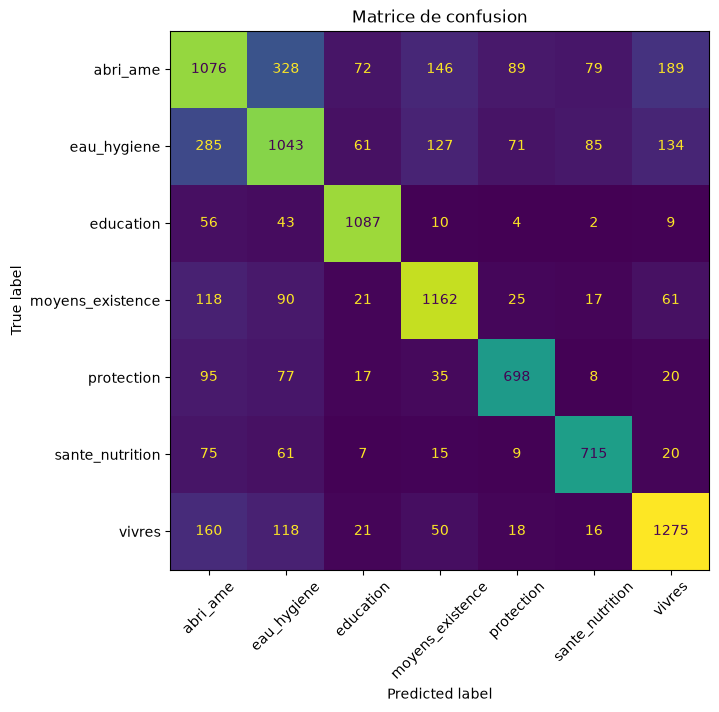

In [27]:
confusion_matrix_func(lg, x_test, y_test)

### <font color = 'teal'>Support Vectors Machines (SVM)<font>

In [28]:
from sklearn.svm import LinearSVC
param_ = {'C': [0.01, 0.1, 1, 10]}
svm = LinearSVC(dual = False, max_iter = 5000)
grid_ = GridSearchCV(svm, param_, cv = 3, n_jobs = -1)
grid_.fit(x_grid, y_grid)
grid_.best_params_

{'C': 1}

In [29]:
svm_model = LinearSVC(dual = False, max_iter = 5000, C = grid_.best_params_['C'])
svm_model.fit(x_train, y_train)
score_svm_test = evaluation(svm_model, 'SVM', 'test', x_test, y_test)
score_models.append(score_svm_test)
score_svm_val = evaluation(svm_model, 'SVM', 'validation', x_val, y_val)
score_models.append(score_svm_val)

Accuracy: 0.695 -- F1 score: 0.711 -- Recall: 0.719 -- Precision: 0.705
Accuracy: 0.689 -- F1 score: 0.706 -- Recall: 0.713 -- Precision: 0.702


### <font color = 'teal'>Decision Tree<font>

In [30]:
from sklearn.tree import DecisionTreeClassifier
param__ = {'criterion':['gini','entropy'],'max_depth':np.arange(4, 21, 2)}
dt = DecisionTreeClassifier(random_state = 42)
grid__ = GridSearchCV(dt, param__, cv = 3, n_jobs = -1)
grid__.fit(x_train, y_train)
grid__.best_params_

{'criterion': 'gini', 'max_depth': np.int64(20)}

In [31]:
dt_model = DecisionTreeClassifier(random_state = 42, **grid__.best_params_)
dt_model.fit(x_train, y_train)
evaluation_dt_test = evaluation(dt_model, 'DT', 'test', x_test, y_test)
score_models.append(evaluation_dt_test)
evaluation_dt_val = evaluation(dt_model, 'DT', 'validation', x_val, y_val)
score_models.append(evaluation_dt_val)

Accuracy: 0.721 -- F1 score: 0.706 -- Recall: 0.700 -- Precision: 0.715
Accuracy: 0.723 -- F1 score: 0.707 -- Recall: 0.701 -- Precision: 0.715


### <font color = 'teal'>Random Forest<font>

In [32]:
from sklearn.ensemble import RandomForestClassifier
params = {'n_estimators': [100, 200], 'max_depth' : [10, 20, None]}
rf = RandomForestClassifier(random_state = 42)
grid = GridSearchCV(estimator=rf, param_grid=params, cv = 3, n_jobs = -1)
grid.fit(x_grid, y_grid)
grid.best_params_

{'max_depth': None, 'n_estimators': 200}

In [33]:
rf = RandomForestClassifier(random_state = 42, n_jobs = -1, **grid.best_params_)
rf.fit(x_train, y_train)
rf_score_test = evaluation(rf, 'RF', 'test', x_test, y_test)
score_models.append(rf_score_test)
rf_score_val = evaluation(rf, 'RF', 'validation', x_val, y_val)
score_models.append(rf_score_val)

Accuracy: 0.795 -- F1 score: 0.788 -- Recall: 0.779 -- Precision: 0.806


Accuracy: 0.787 -- F1 score: 0.779 -- Recall: 0.771 -- Precision: 0.796


### <font color = 'teal'>XGBoost<font>

In [34]:
# Recherche des paramètres optimaux pour XGBoost
# avec 7 classes, XGBoost construit 7 arbres par tour : on cherche sur l'échantillon de 20 000 ménages
from xgboost import XGBClassifier
params__ = {  "n_estimators": [1000, 2000],
              "max_depth": [4, 6]}
xgb = XGBClassifier(learning_rate = 0.05, subsample = 0.8, colsample_bytree = 0.8, random_state = 42)
grid__ = GridSearchCV(estimator=xgb, param_grid=params__, cv = 3)
grid__.fit(x_grid, y_grid)
grid__.best_params_

{'max_depth': 4, 'n_estimators': 1000}

In [35]:
# Entrainer le modèle en utilisant les paramètres optimaux sur toutes les données d'entrainement
xgb = XGBClassifier(learning_rate = 0.05, subsample = 0.8, colsample_bytree = 0.8, random_state = 42, **grid__.best_params_)
xgb.fit(x_train, y_train)

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn

#### Evaluation XGBoost

In [36]:
eval_xgb_test = evaluation(xgb, 'XGB','test', x_test, y_test)
score_models.append(eval_xgb_test)
eval_xgb_val = evaluation(xgb, 'XGB','validation', x_val, y_val)
score_models.append(eval_xgb_val)

Accuracy: 0.970 -- F1 score: 0.971 -- Recall: 0.970 -- Precision: 0.971


Accuracy: 0.968 -- F1 score: 0.968 -- Recall: 0.967 -- Precision: 0.969


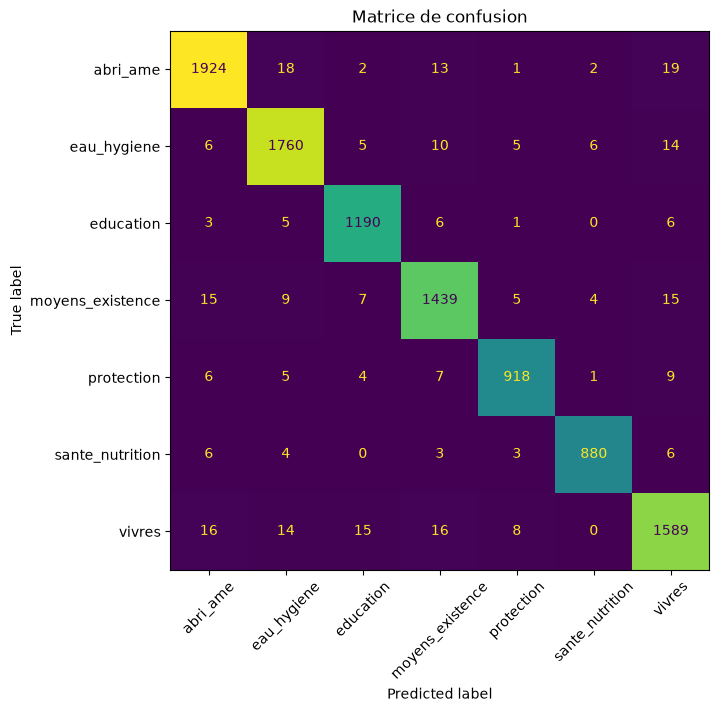

In [37]:
confusion_matrix_func(xgb, x_test, y_test)

#### Recherche du model le plus performant

In [38]:
def model_viz(data, metric, title):
    fig = px.bar(
        x=data.model,
        y=data[metric],
        color=data[metric],
        text_auto='.2%',
        title=title
    )
    max_idx = data[metric].idxmax()
    max_model = data.loc[max_idx, 'model']
    max_value = data.loc[max_idx, metric]
    fig.add_annotation(
        x=max_model,
        y=max_value,
        text="⬆️ Meilleure score",
        showarrow=True,
        arrowhead=2,
        ax=0,
        ay=-40,
        font=dict(color="black", size=12)
    )
    fig.show()

In [39]:
df_score_models = pd.DataFrame(score_models)
df_score_test = df_score_models[df_score_models["type_data"] == "test"]
df_score_val = df_score_models[df_score_models["type_data"] == "validation"]
df_score_test

,model,accuracy,f1_score,recall,precision,type_data
0,KNN,0.5274,0.461012,0.475347,0.548176,test
2,LG,0.7056,0.724381,0.727576,0.721796,test
4,SVM,0.6946,0.711094,0.718877,0.704978,test
6,DT,0.7212,0.705554,0.700049,0.714526,test
8,RF,0.7951,0.787580,0.779304,0.805577,test
10,XGB,0.9700,0.970836,0.970413,0.971281,test


In [40]:
model_viz(df_score_test, "accuracy", "Accuracy on test data")
model_viz(df_score_test, "f1_score", "F1 Score (macro) on test data")
model_viz(df_score_val, "f1_score", "F1 Score (macro) on validation data")

## Le model le plus performant est XGB

In [41]:
# score de chaque type d'assistance
from sklearn.metrics import classification_report
y_pred = xgb.predict(x_test)
print(classification_report(y_test, y_pred, target_names = classes, digits = 3))

                  precision    recall  f1-score   support

        abri_ame      0.974     0.972     0.973      1979
     eau_hygiene      0.970     0.975     0.972      1806
       education      0.973     0.983     0.978      1211
moyens_existence      0.963     0.963     0.963      1494
      protection      0.976     0.966     0.971       950
 sante_nutrition      0.985     0.976     0.981       902
          vivres      0.958     0.958     0.958      1658

        accuracy                          0.970     10000
       macro avg      0.971     0.970     0.971     10000
    weighted avg      0.970     0.970     0.970     10000



In [42]:
f1_classes = pd.Series(f1_score(y_test, y_pred, average = None), index = classes).sort_values()
fig = px.bar(x = f1_classes.index, y = f1_classes.values, color = f1_classes.values, text_auto = '.1%', title = "XGBoost : F1 score de chaque type d'assistance")
fig.add_hline(y = 0.95, line_dash = 'dash', annotation_text = "95%")
fig.update_yaxes(range = [0.85, 1])
fig.show()

In [43]:
# et pour les ménages éligibles, ceux qui recevront vraiment l'assistance ?
eligible_test = eligible[idx_test] == 1
print(f"Ménages éligibles dans le jeu de test : {eligible_test.sum()}")
print(f"Accuracy sur les éligibles : {accuracy_score(y_test[eligible_test], y_pred[eligible_test]):.3f}")
print(f"F1 score (macro) sur les éligibles : {f1_score(y_test[eligible_test], y_pred[eligible_test], average = 'macro'):.3f}")

Ménages éligibles dans le jeu de test : 2966
Accuracy sur les éligibles : 0.959
F1 score (macro) sur les éligibles : 0.955


#### Le score est-il stable ?
Validation croisée en 5 parties sur les données d'entrainement.

In [44]:
from sklearn.model_selection import cross_validate
cv_xgb = cross_validate(XGBClassifier(learning_rate = 0.05, subsample = 0.8, colsample_bytree = 0.8, random_state = 42, **grid__.best_params_),
                        x_train, y_train, cv = 5, scoring = ['accuracy', 'f1_macro', 'recall_macro', 'precision_macro'])
df_cv = pd.DataFrame(cv_xgb).filter(like = 'test_')
df_cv.columns = ['accuracy', 'f1_score', 'recall', 'precision']
df_cv

,accuracy,f1_score,recall,precision
0,0.966750,0.967113,0.966246,0.968006
1,0.964938,0.964943,0.964225,0.965688
2,0.966313,0.967024,0.966261,0.967847
3,0.965875,0.965735,0.965149,0.966344
4,0.966875,0.966854,0.965837,0.967935


In [45]:
df_cv.describe().loc[['mean', 'min', 'max']]

,accuracy,f1_score,recall,precision
mean,0.966150,0.966334,0.965544,0.967164
min,0.964938,0.964943,0.964225,0.965688
max,0.966875,0.967113,0.966261,0.968006


#### Les 2 meilleures propositions

Un ménage a souvent plusieurs besoins. Le modèle donne une probabilité pour chaque type d'assistance : on peut proposer au superviseur les deux plus probables. On regarde si l'assistance retenue par le comité est dans ces deux propositions.

In [46]:
proba = xgb.predict_proba(x_test)
top2 = np.argsort(-proba, axis = 1)[:, :2]
dans_top2 = (top2 == y_test[:, None]).any(axis = 1)
print(f"Assistance du comité parmi les 2 propositions du modèle : {dans_top2.mean():.1%}")

Assistance du comité parmi les 2 propositions du modèle : 99.8%


In [47]:
# exemple : 8 ménages éligibles du jeu de test
exemple = np.where(eligible_test)[0][:8]
pd.DataFrame({
    'comité': classes[y_test[exemple]],
    'modèle': classes[y_pred[exemple]],
    'probabilité': proba[exemple].max(axis = 1).round(3),
    '2e proposition': classes[top2[exemple, 1]],
})

,comité,modèle,probabilité,2e proposition
0,abri_ame,abri_ame,0.972,sante_nutrition
1,sante_nutrition,sante_nutrition,0.736,education
2,vivres,vivres,0.970,moyens_existence
3,moyens_existence,vivres,0.588,moyens_existence
4,protection,protection,0.908,abri_ame
5,vivres,vivres,0.739,moyens_existence
6,moyens_existence,eau_hygiene,0.578,moyens_existence
7,moyens_existence,moyens_existence,0.999,eau_hygiene


#### Importance des variables

In [48]:
imp = pd.Series(xgb.feature_importances_, index = noms_variables).sort_values().tail(20)
fig = px.bar(x = imp.values, y = imp.index, color = imp.values, orientation = 'h', height = 700, title = "XGBoost : importance des variables (type d'assistance)")
fig.show()

## SHAP values

In [49]:
import shap
x_test2 = pd.DataFrame(x_test, columns = noms_variables)
x_test_brut = df_model.drop('assistance_ideale', axis=1).loc[idx_test].reset_index(drop = True)

explainer = shap.Explainer(xgb)
shap_values = explainer(x_test2[:500])
shap_values.data = x_test_brut[:500].values
np.shape(shap_values.values) # ménages, variables, classes

(500, 77, 7)

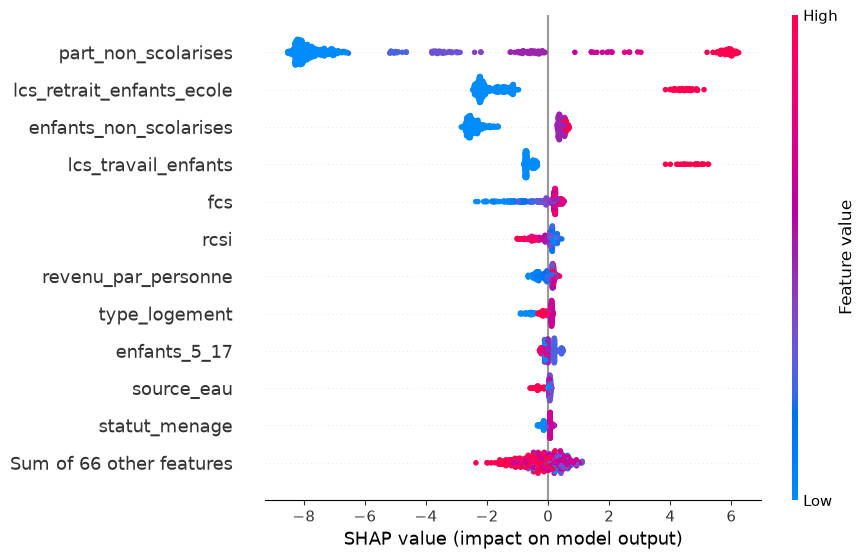

In [50]:
# qu'est-ce qui pousse le modèle vers l'assistance "éducation" ?
k = list(classes).index('education')
shap.plots.beeswarm(shap_values[:, :, k], max_display = 12)

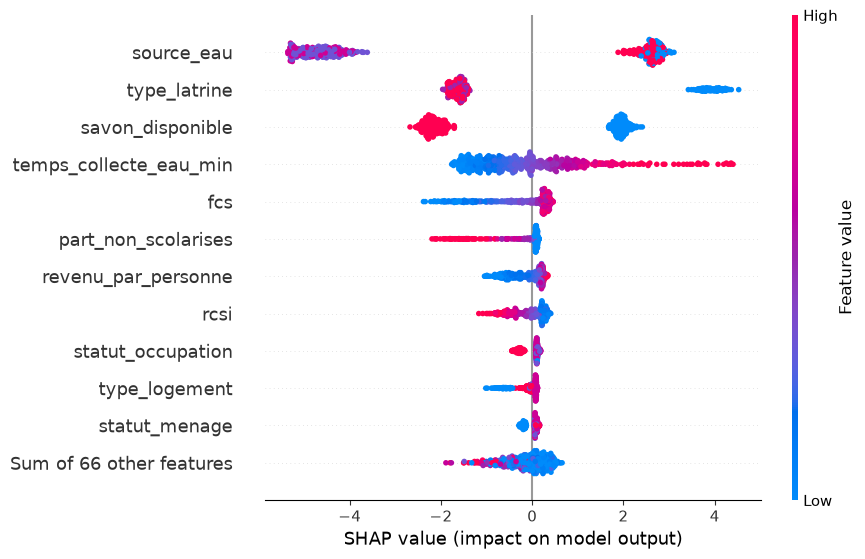

In [51]:
# et vers "eau, hygiène et assainissement" ?
k = list(classes).index('eau_hygiene')
shap.plots.beeswarm(shap_values[:, :, k], max_display = 12)

Assistance proposée : abri_ame


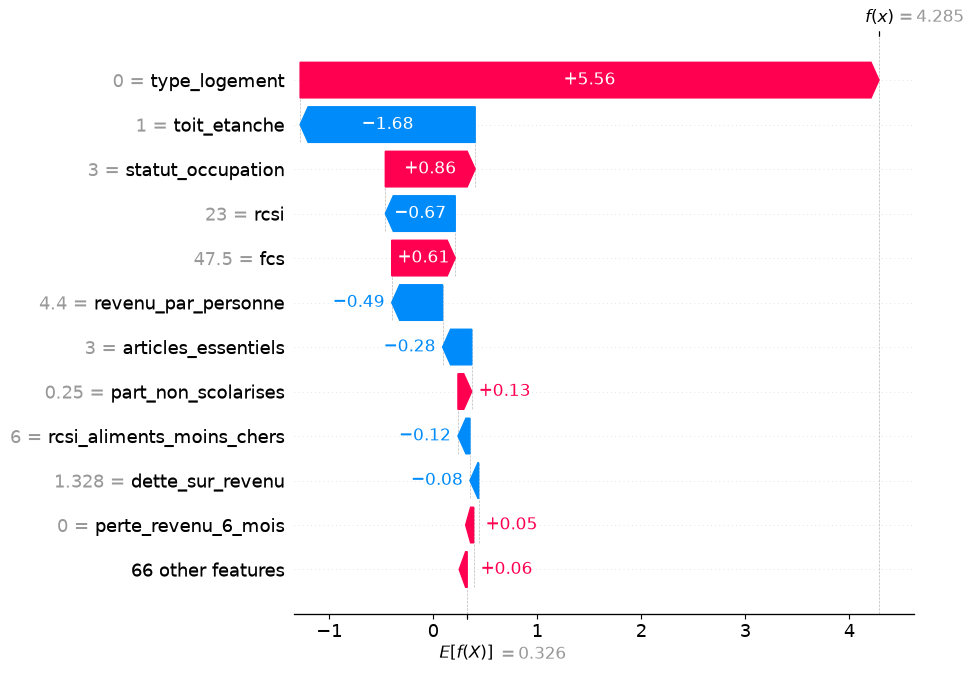

In [52]:
# un ménage du jeu de test : pourquoi le modèle propose cette assistance
i = int(exemple[0])
k = int(y_pred[i])
print(f"Assistance proposée : {classes[k]}")
shap.plots.waterfall(shap_values[i, :, k], max_display = 12)

## Conclusion

- À partir des mêmes réponses que pour l'éligibilité, le modèle prédit aussi le **type d'assistance idéale** parmi 7 types (classification multi classe).
- **XGBoost est encore le modèle le plus performant** : sur les données de test, accuracy 97,0 % et F1 score (macro) 97,1 %, et au moins 95,8 % de F1 pour chacun des 7 types d'assistance. Sur les ménages éligibles, qui ont souvent plusieurs besoins à la fois, l'accuracy est de 95,9 % (F1 macro 95,5 %). En validation croisée, aucune partie ne descend sous 96,4 %.
- Les autres modèles sont loin derrière (Random Forest 79,5 %, régression logistique 70,6 %, KNN 52,7 %) : les modèles linéaires ne savent pas comparer les besoins des différents secteurs entre eux.
- Dans 99,8 % des cas, l'assistance retenue par le comité est parmi les 2 propositions du modèle.
- Le modèle donne une probabilité pour chaque type d'assistance : le dashboard affiche la proposition principale et les alternatives, et le superviseur garde la décision.
- Utilisation : préparer une distribution par type d'assistance (par exemple, une distribution de kits scolaires pour les ménages éligibles dont le besoin principal est l'éducation), et orienter les ménages non éligibles vers le bon partenaire.

Le modèle déployé dans l'API est entraîné par `training/train.py`, avec la même préparation et les mêmes paramètres.